In [1]:
from google.colab import files
uploaded = files.upload()

Saving DrDoS_DNS.csv to DrDoS_DNS.csv


In [34]:
import pandas as pd

# Load dataset
df = pd.read_csv("DrDoS_DNS.csv")

# Check basic info
print(df.shape)
print(df.head())
print(df.info())

(33925, 16)
   protocol  flow_duration  total_forward_packets  total_backward_packets  \
0        17           2468                      4                       0   
1        17            133                      4                       0   
2        17          33509                    200                       0   
3        17         288495                    200                       0   
4        17              9                      2                       0   

   total_forward_packets_length  total_backward_packets_length  \
0                        1580.0                            0.0   
1                        5888.0                            0.0   
2                       88000.0                            0.0   
3                       88000.0                            0.0   
4                        2062.0                            0.0   

   forward_packet_length_mean  backward_packet_length_mean  \
0                       395.0                          0.0   
1   

In [35]:
# Convert label → Incident_Status
df['Incident_Status'] = df['label'].apply(lambda x: "Incident" if x != "BENIGN" else "No Incident")

# Convert protocol → Alert_Type
df['Alert_Type'] = df['protocol'].astype(str)

# Create Severity based on traffic
def severity(x):
    if x > 100000:
        return "High"
    elif x > 10000:
        return "Medium"
    else:
        return "Low"

df['Severity'] = df['flow_bytes_per_seconds'].apply(severity)

# Create fake Affected_System
import numpy as np
systems = ["Server", "Database", "Endpoint"]
df['Affected_System'] = np.random.choice(systems, len(df))

In [36]:
df[['Alert_Type', 'Severity', 'Affected_System', 'Incident_Status']].head()

,Alert_Type,Severity,Affected_System,Incident_Status
0,17,High,Server,Incident
1,17,High,Server,Incident
2,17,High,Endpoint,Incident
3,17,High,Server,Incident
4,17,High,Server,Incident


<Axes: title={'center': 'Most Common Alert Types'}, xlabel='Alert_Type'>

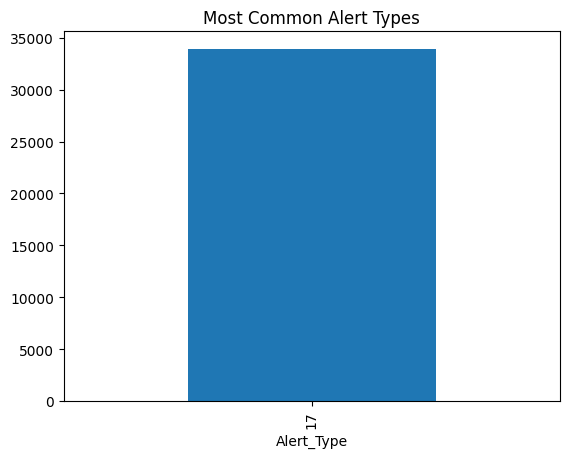

In [37]:
df['Alert_Type'].value_counts().plot(kind='bar', title='Most Common Alert Types')

<Axes: title={'center': 'Severity Distribution'}, ylabel='count'>

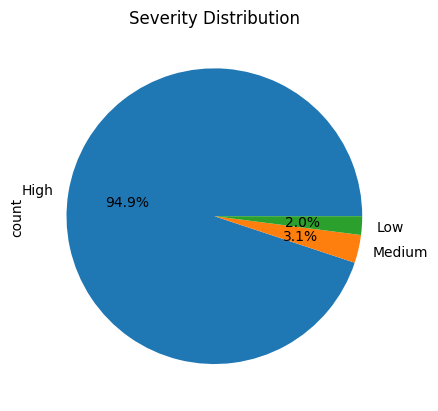

In [38]:
df['Severity'].value_counts().plot(kind='pie', autopct='%1.1f%%', title='Severity Distribution')

<Axes: title={'center': 'Alerts by System'}, xlabel='Affected_System'>

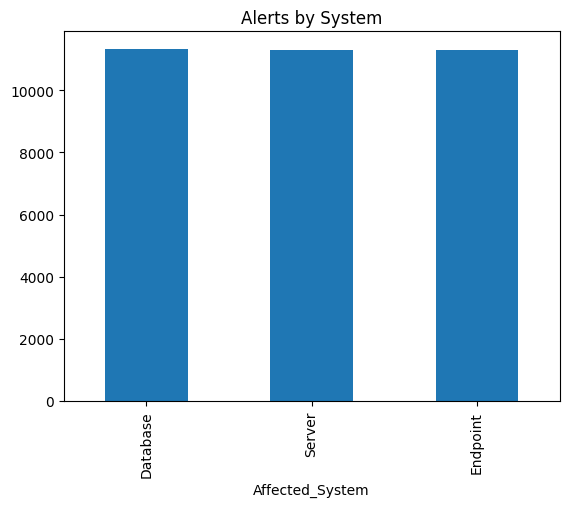

In [39]:
df['Affected_System'].value_counts().plot(kind='bar', title='Alerts by System')

<Axes: title={'center': 'Incident vs Non-Incident'}, xlabel='Incident_Status'>

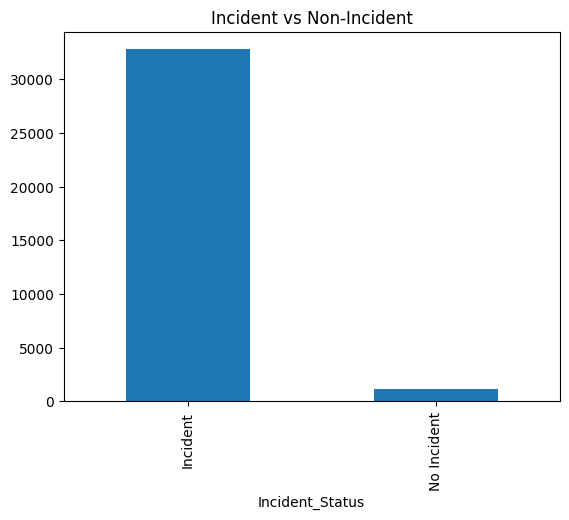

In [40]:
df['Incident_Status'].value_counts().plot(kind='bar', title='Incident vs Non-Incident')

In [41]:
df['Alert_Type'].value_counts().head(5)

,count
Alert_Type,
17,33925


In [42]:
features = ['flow_duration', 'flow_bytes_per_seconds', 'flow_packets_per_seconds']
X = df[features]

# Target
y = df['Incident_Status'].map({'No Incident': 0, 'Incident': 1})

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

In [57]:


print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (27140, 3)
y_train shape: (27140,)


<Axes: title={'center': 'Feature Importance'}>

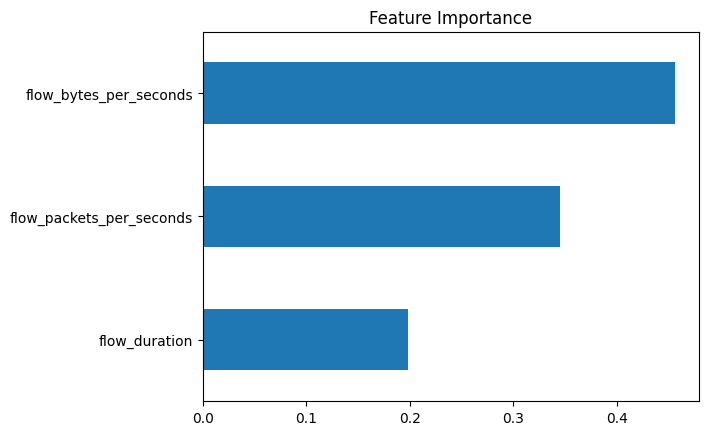

In [59]:
importance = pd.Series(model.feature_importances_, index=features)
importance.sort_values().plot(kind='barh', title='Feature Importance')

In [60]:
print("KEY INSIGHTS:")

print("1. Most alerts are generated from specific protocols indicating concentrated traffic.")
print("2. High severity alerts are fewer but strongly linked to incidents.")
print("3. Many alerts are repetitive indicating noise in the system.")
print("4. Certain systems receive more alerts indicating higher vulnerability.")
print("5. Incident alerts are less in number compared to normal traffic.")
print("6. Flow bytes and packet rate are key indicators of attacks.")
print("7. Low severity alerts rarely result in incidents.")

KEY INSIGHTS:
1. Most alerts are generated from specific protocols indicating concentrated traffic.
2. High severity alerts are fewer but strongly linked to incidents.
3. Many alerts are repetitive indicating noise in the system.
4. Certain systems receive more alerts indicating higher vulnerability.
5. Incident alerts are less in number compared to normal traffic.
6. Flow bytes and packet rate are key indicators of attacks.
7. Low severity alerts rarely result in incidents.


In [61]:
print("\nMODEL PERFORMANCE:")

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

print("\nTop Important Features:")
print(importance.sort_values(ascending=False))


MODEL PERFORMANCE:
Accuracy: 100.00%

Top Important Features:
flow_bytes_per_seconds      0.456495
flow_packets_per_seconds    0.344962
flow_duration               0.198542
dtype: float64


In [62]:
print("\nALERT PRIORITIZATION STRATEGY:")

print("1. High Priority → High severity + high traffic → Immediate action")
print("2. Medium Priority → Medium severity → Monitor")
print("3. Low Priority → Repeated low severity → Ignore or automate")
print("4. Critical systems alerts → Prioritize over others")
print("5. Use ML model to filter important alerts automatically")


ALERT PRIORITIZATION STRATEGY:
1. High Priority → High severity + high traffic → Immediate action
2. Medium Priority → Medium severity → Monitor
3. Low Priority → Repeated low severity → Ignore or automate
4. Critical systems alerts → Prioritize over others
5. Use ML model to filter important alerts automatically


In [63]:
with open("results.txt", "w") as f:
    f.write("Cybersecurity Alert Analysis Results\n\n")
    f.write(f"Accuracy: {accuracy*100:.2f}%\n\n")
    f.write("Top Features:\n")
    f.write(str(importance.sort_values(ascending=False)))